# Учебное исследование города Приморск (Выборгский район, Ленинградская область, Россия) с помощью BlocksNet 1.0.0.a9

**Цель:** подготовить данные, выделить городские кварталы, загрузить пешеходный граф дорожной сети и посчитать *все* показатели из `examples/pipeline.ipynb` для города Приморск.

**Важные ограничения:**
- Рабочая среда: Windows. Все команды ниже даны под PowerShell.
- Версия библиотеки: `blocksnet == 1.0.0a9` (установлена в окружении).
- Только пешеходный граф (`network_type='walk'`), без интермодального расчёта.
- Скачивание данных, расчёты и построение графа **выполняешь самостоятельно** при запуске ячеек ноутбука. Я ничего не скачивал и не запускал.
- Используется **только** граница города Приморск (не всё Приморское городское поселение).
- Результаты сохраняются в `GeoJSON`. Весь промежуточный результат можно переиспользовать без повторного скачивания.
- Расчёт времени в пути выполняется по **только одному** пешеходному графу, время переводится в **минуты**.

## 1. Подготовка окружения

В этом блоке - только проверка. **Ничего не устанавливаем.** Опираемся на существующий `pyproject.toml` текущего проекта.

**Проверка зависимостей из pyproject.toml:**
- В `dependencies` текущего `pyproject.toml` блок `blocksnet` отсутствует. Это нужно будет добавить в дальнейшем при подготовке окружения под публикацию/развёртывание. **Второй файл зависимостей создавать не будем**.
- Для работы по пайплайну потребуются: `blocksnet==1.0.0a9`, `geopandas`, `osmnx`, `networkx`, `shapely`, `pyproj`, `matplotlib` (для быстрой визуальной проверки).

In [1]:
# Проверка версий установленных библиотек (только чтение)
import sys
print('Python:', sys.version)

try:
    import blocksnet
    print('blocksnet:', blocksnet.__version__)
except Exception as e:
    print('blocksnet: НЕ НАЙДЕН -', e)

try:
    import geopandas as gpd
    print('geopandas:', gpd.__version__)
except Exception as e:
    print('geopandas: НЕ НАЙДЕН -', e)

try:
    import osmnx as ox
    print('osmnx:', ox.__version__)
except Exception as e:
    print('osmnx: НЕ НАЙДЕН -', e)

try:
    import networkx as nx
    print('networkx:', nx.__version__)
except Exception as e:
    print('networkx: НЕ НАЙДЕН -', e)

try:
    import shapely
    print('shapely:', shapely.__version__)
except Exception as e:
    print('shapely: НЕ НАЙДЕН -', e)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
blocksnet: 1.0.0a9
geopandas: 1.2.0
osmnx: 2.1.1
networkx: 3.6.1
shapely: 2.2.0


### Команды для Windows (PowerShell) для работы с ноутбуком

Выполняй по мере надобности **в терминале PowerShell** из корня проекта:

```powershell
# Активировать venv, если используется
.\.venv\Scripts\Activate.ps1

# Запуск Jupyter Lab
jupyter lab

# Или Jupyter Notebook
jupyter notebook
```

**Порядок работы:** запускай ячейки по порядку. **После раздела 3** будет явная остановка - не переходи к расчёту показателей, пока не задумаешься о доступных метриках (как указано ниже).

## 2. Структура папок для данных

Создадим папку для всех исходных, промежуточных и итоговых файлов. Будем проверять наличие файлов и при повторном запуске использовать уже сохранённые.

Путь: `data/primorsk_blocksnet/`

In [2]:
from pathlib import Path

DATA_DIR = Path('data/primorsk_blocksnet')
DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Папка данных:', DATA_DIR.resolve())

# Пути под сохранение
PATH_BOUNDARY = DATA_DIR / 'boundary_primorsk.geojson'
PATH_WATER = DATA_DIR / 'water.geojson'
PATH_ROADS = DATA_DIR / 'roads.geojson'
PATH_RAILWAYS = DATA_DIR / 'railways.geojson'
PATH_BLOCKS = DATA_DIR / 'blocks.geojson'
PATH_GRAPH_GraphML = DATA_DIR / 'graph.graphml'
PATH_INDICATORS = DATA_DIR / 'indicators.geojson'

print('Готовые пути настроены.')

Папка данных: D:\ИТМО\Курс ИИ технологии\python-package-boilerplate\data\primorsk_blocksnet
Готовые пути настроены.


## 3. Загрузка границ и исходных слоёв. Подготовка кварталов

Здесь мы получаем **только границу города Приморск** (Выборгский район, Ленинградская область, Россия). Важно: не Приморское городское поселение целиком, а именно город Приморск.

Будем использовать подход из `examples/pipeline.ipynb` с `osmnx.geocode_to_gdf`, фильтровать по типам геометрии, приводить к UTM CRS, предобрабатывать и нарезать кварталы через `blocksnet.blocks.cutting`.

### 3.1. Получение границы города Приморск (с визуальной проверкой)

**Пояснения простыми словами:**
- Сначала пробуем точный запрос: `"Приморск, Выборгский район, Ленинградская область, Россия"` или вариант `"город Приморск"`. 
- Далее **обязательно** делаем визуальную проверку границы на карте, чтобы убедиться, что это именно город, а не всё поселение.
- Если при проверке граница окажется слишком большой (включает окрестные территории поселения) - вместо простого geocode лучше будет использовать более точный поиск/фильтрацию. Но для начала делаем именно так, как в примере, с проверкой.

Файл границы не найден. Будет выполнен запрос через osmnx.geocode_to_gdf.
Запрос: "Приморск, Выборгский район, Ленинградская область, Россия"
Граница сохранена в: data\primorsk_blocksnet\boundary_primorsk.geojson


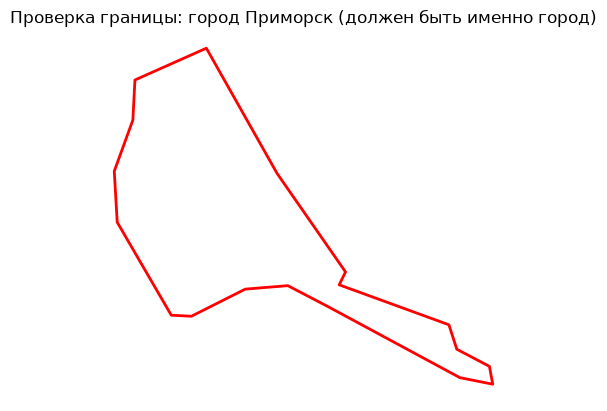

                                            geometry  bbox_west  bbox_south  \
0  POLYGON ((28.59984 60.36833, 28.59989 60.36793...  28.599844   60.340777   

   bbox_east  bbox_north   place_id osm_type     osm_id        lat        lon  \
0  28.698837   60.384238  176929961      way  100648422  60.366665  28.616673   

   class  type  place_rank  importance addresstype      name  \
0  place  town          18    0.532846        town  Primorsk   

                                        display_name  
0  Primorsk, Приморское городское поселение, Vybo...  


In [3]:
# Загрузка границы с проверкой наличия сохранённого файла
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

if PATH_BOUNDARY.exists():
    print('Найден сохранённый файл границы:', PATH_BOUNDARY)
    boundaries = gpd.read_file(PATH_BOUNDARY)
    print('Загружено из файла.')
else:
    print('Файл границы не найден. Будет выполнен запрос через osmnx.geocode_to_gdf.')
    print('Запрос: "Приморск, Выборгский район, Ленинградская область, Россия"')
    # ВАЖНО: запуск этой ячейки выполнит запрос к OSM. Ты запускаешь самостоятельно.
    boundaries = ox.geocode_to_gdf('Приморск, Выборгский район, Ленинградская область, Россия')
    # Сохраняем сразу для повторного использования
    boundaries.to_file(PATH_BOUNDARY, driver='GeoJSON')
    print('Граница сохранена в:', PATH_BOUNDARY)

# Визуальная проверка границы
ax = boundaries.plot(edgecolor='red', facecolor='none', linewidth=2)
ax.set_title('Проверка границы: город Приморск (должен быть именно город)')
ax.set_axis_off()
plt.show()

print(boundaries)

### 3.2. Загрузка дорог, ж/д, водных объектов по тегам (как в pipeline)

Используем теги из примера BlocksNet. Сохраняем слои в GeoJSON для повторного использования.

In [6]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.use_cache = True
ox.settings.overpass_rate_limit = True

print("Сервер Overpass настроен:", ox.settings.overpass_url)

Сервер Overpass настроен: https://overpass.kumi.systems/api


In [9]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.requests_timeout = 120
ox.settings.use_cache = True

print("Настройки OSMnx обновлены")

Настройки OSMnx обновлены


In [ ]:
bc_tags = {
    'roads': {
      "highway": ["living_street","pedestrian","primary","residential","road","secondary","services","tertiary","unclassified"],
      "service": ["living_street", "emergency_access"]
    },
    'railways': {
      "railway": "rail"
    },
    'water': {
      'riverbank':True,
      'reservoir':True,
      'basin':True,
      'dock':True,
      'canal':True,
      'pond':True,
      'natural': ['water', 'bay', 'strait'],
      'waterway':['river','canal','ditch'],
      'landuse':'basin',
      'water': 'lake'
    }
}

# Загрузка с проверкой файлов
def load_or_fetch_features(polygon_gdf, tags, save_path, name):
    if save_path.exists():
        print(f'{name}: найден сохранённый файл {save_path}, загружаем...')
        gdf = gpd.read_file(save_path)
        return gdf
    else:
        print(f'{name}: файла нет. Будет загрузка через ox.features_from_polygon (запуском ячейки).')
        # union_all для совместимости
        try:
            poly = polygon_gdf.union_all()
        except Exception:
            poly = polygon_gdf.geometry.unary_union
        gdf = ox.features_from_polygon(poly, tags)
        gdf.to_file(save_path, driver='GeoJSON')
        print(f'{name}: сохранён в {save_path}')
        return gdf

# Получаем данные
water = load_or_fetch_features(boundaries, bc_tags['water'], PATH_WATER, 'water')
roads = load_or_fetch_features(boundaries, bc_tags['roads'], PATH_ROADS, 'roads')
railways = load_or_fetch_features(boundaries, bc_tags['railways'], PATH_RAILWAYS, 'railways')

print('Слои загружены.')

water: найден сохранённый файл data\primorsk_blocksnet\water.geojson, загружаем...
roads: найден сохранённый файл data\primorsk_blocksnet\roads.geojson, загружаем...
railways: найден сохранённый файл data\primorsk_blocksnet\railways.geojson, загружаем...
Слои загружены.


### 3.3. Фильтрация геометрий и приведение к CRS

Фильтруем по типам геометрий как в примере, переводим всё в UTM для корректной нарезки.

UTM CRS: EPSG:32635
CRS приведён.


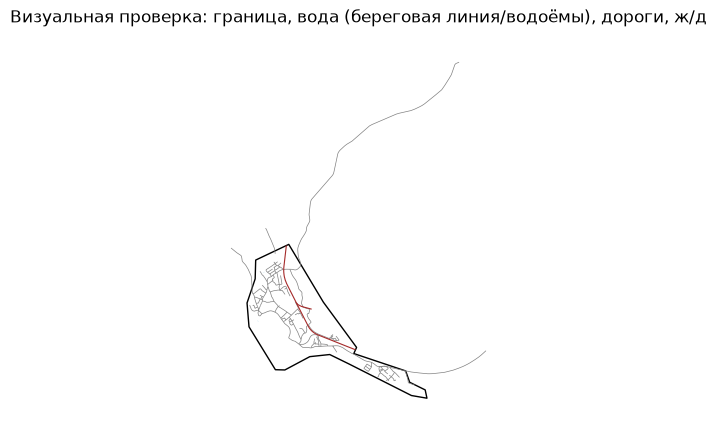

In [15]:
# Фильтрация
water_f = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].copy()
roads_f = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].copy()
railways_f = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].copy()
boundaries_f = boundaries.copy()

# CRS
crs = boundaries_f.estimate_utm_crs()
print('UTM CRS:', crs)

for gdf in [water_f, roads_f, railways_f, boundaries_f]:
    gdf.to_crs(crs, inplace=True)

print('CRS приведён.')

# Визуальная проверка береговой линии и транспортной сети
ax = boundaries_f.plot(edgecolor='black', facecolor='none')
water_f.plot(ax=ax, color='lightblue', alpha=0.6)
roads_f.plot(ax=ax, color='grey', linewidth=0.5)
railways_f.plot(ax=ax, color='brown', linewidth=0.8)
ax.set_title('Визуальная проверка: граница, вода (береговая линия/водоёмы), дороги, ж/д')
ax.set_axis_off()
plt.show()

### 3.4. Предобработка и нарезка городских кварталов

Используем `preprocess_urban_objects` и `cut_urban_blocks` из `blocksnet.blocks.cutting` как в `pipeline.ipynb`.

Участков береговой линии: 3


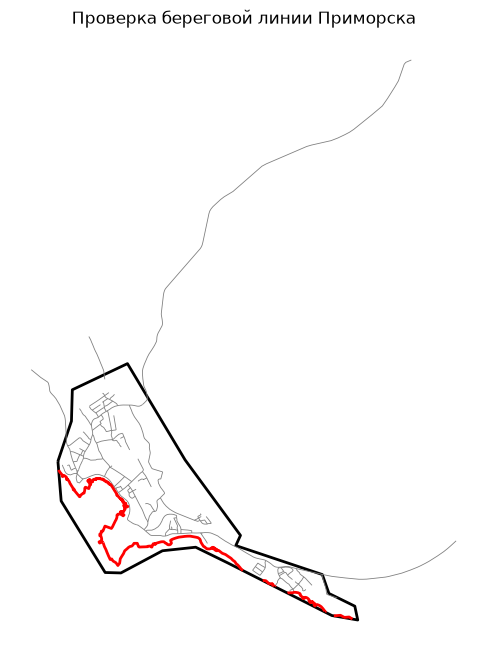

In [17]:

import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from pathlib import Path

PATH_COAST = DATA_DIR / "coastline.geojson"

if PATH_COAST.exists():
    coastline = gpd.read_file(PATH_COAST).to_crs(crs)
    print("Береговая линия загружена из файла.")
else:
    # Ищем береговую линию с запасом 500 м
    search_area = boundaries_f.buffer(500).union_all()
    search_area = gpd.GeoSeries(
        [search_area], crs=crs
    ).to_crs(4326).iloc[0]

    coastline = ox.features_from_polygon(
        search_area,
        {"natural": "coastline"}
    )

    coastline = coastline[
        coastline.geom_type.isin(
            ["LineString", "MultiLineString"]
        )
    ].copy().to_crs(crs)

    coastline = gpd.clip(coastline, boundaries_f)
    coastline = coastline[
        coastline.geom_type.isin(
            ["LineString", "MultiLineString"]
        )
    ].copy()

    if not coastline.empty:
        coastline.to_file(PATH_COAST, driver="GeoJSON")

print("Участков береговой линии:", len(coastline))

fig, ax = plt.subplots(figsize=(10, 8))
boundaries_f.boundary.plot(
    ax=ax, color="black", linewidth=2
)
roads_f.plot(ax=ax, color="gray", linewidth=0.6)

if not coastline.empty:
    coastline.plot(ax=ax, color="red", linewidth=2)

ax.set_title("Проверка береговой линии Приморска")
ax.set_axis_off()
plt.show()
  

In [18]:
import pandas as pd

coastline_f = coastline.to_crs(crs)

water_f = gpd.GeoDataFrame(
    pd.concat(
        [
            water_f[['geometry']],
            coastline_f[['geometry']]
        ],
        ignore_index=True
    ),
    geometry='geometry',
    crs=crs
)

print("Водных объектов и участков берега:",
      len(water_f))

Водных объектов и участков берега: 7


Polygon            4
MultiLineString    2
LineString         1
Name: count, dtype: int64


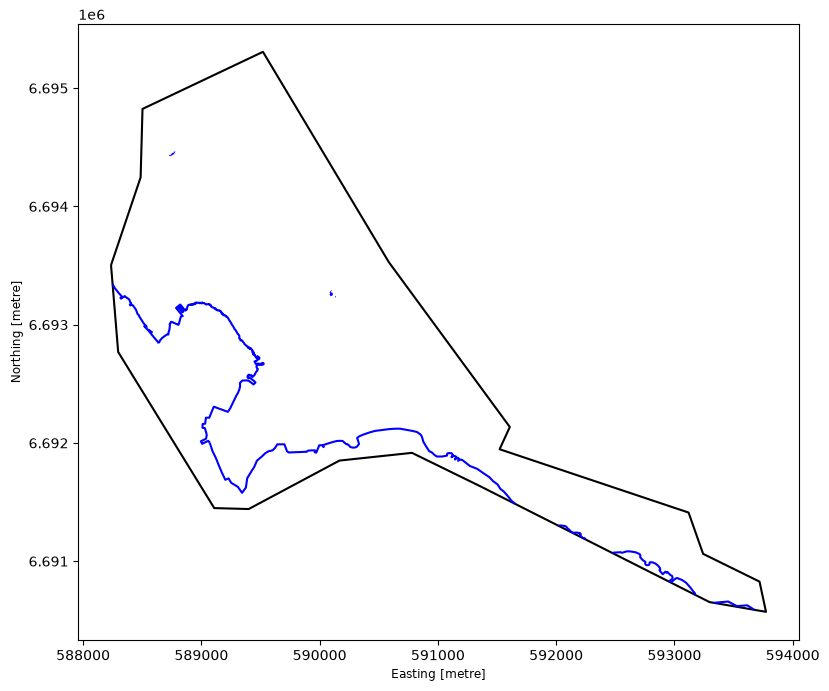

In [19]:
print(water_f.geom_type.value_counts())

ax = boundaries_f.boundary.plot(
    color='black', figsize=(10, 8)
)
water_f.plot(
    ax=ax, color='blue', linewidth=1.5
)
plt.show()

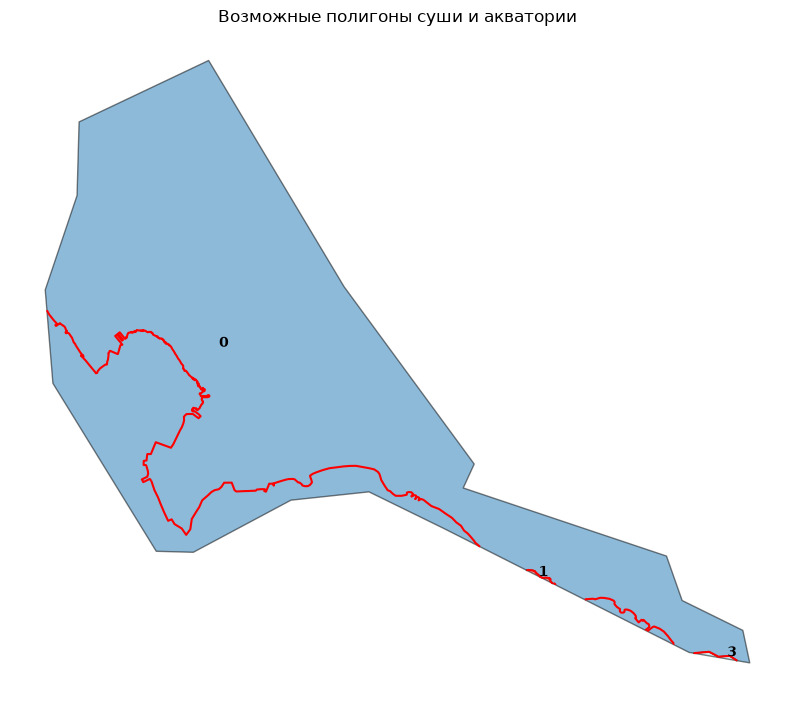

Получено полигонов: 3
   id
3   3
1   1
0   0


In [21]:

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.ops import unary_union, polygonize

coast = coastline.to_crs(crs)

boundary_line = boundaries_f.geometry.boundary.union_all()

combined_lines = unary_union([
    boundary_line,
    coast.geometry.union_all()
])

candidate_polygons = list(polygonize(combined_lines))

candidates = gpd.GeoDataFrame(
    {"id": range(len(candidate_polygons))},
    geometry=candidate_polygons,
    crs=crs
)

candidates = gpd.clip(candidates, boundaries_f)
candidates = candidates[candidates.area > 100].copy()

fig, ax = plt.subplots(figsize=(10, 9))

candidates.plot(
    ax=ax,
    column="id",
    cmap="tab20",
    alpha=0.5,
    edgecolor="black"
)

for _, row in candidates.iterrows():
    p = row.geometry.representative_point()
    ax.text(
        p.x, p.y, str(row["id"]),
        fontsize=10, weight="bold"
    )

coast.plot(
    ax=ax, color="red", linewidth=1.5
)

ax.set_title("Возможные полигоны суши и акватории")
ax.set_axis_off()
plt.show()

print("Получено полигонов:", len(candidates))
print(candidates[["id"]])
  

In [22]:

import osmnx as ox
import geopandas as gpd

# Дополнительные теги для поиска акватории
water_extra_tags = {
    "natural": ["strait", "bay", "water"],
    "water": ["strait", "sea"],
    "place": ["sea", "locality"]
}

search_polygon = boundaries.to_crs(4326).buffer(0.02).union_all()

water_extra = ox.features_from_polygon(
    search_polygon,
    water_extra_tags
)

print("Найдено объектов:", len(water_extra))
print(water_extra.geom_type.value_counts())

columns = [
    c for c in ["name", "natural", "water", "place"]
    if c in water_extra.columns
]
print(water_extra[columns].to_string())
    

C:\Users\Honor\AppData\Local\Temp\ipykernel_33468\989013670.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  search_polygon = boundaries.to_crs(4326).buffer(0.02).union_all()


Найдено объектов: 7
Polygon       5
Point         1
LineString    1
Name: count, dtype: int64
                                   name natural
element  id                                    
node     13028643061   бухта Катерлахти     bay
relation 9890419      пролив Бьёркезунд  strait
way      93127501                   NaN   water
         93860141                   NaN   water
         93860146                   NaN   water
         137459107                  NaN   water
         171553120    пролив Бьёркезунд  strait


In [23]:
check = water_extra.copy()

check["geometry_type"] = check.geom_type
check["area_km2"] = (
    check.to_crs(32635).geometry.area / 1_000_000
).round(3)

print(
    check[
        ["name", "natural", "geometry_type", "area_km2"]
    ].to_string()
)

                                   name natural geometry_type  area_km2
element  id                                                            
node     13028643061   бухта Катерлахти     bay         Point     0.000
relation 9890419      пролив Бьёркезунд  strait       Polygon    93.943
way      93127501                   NaN   water       Polygon     0.001
         93860141                   NaN   water       Polygon     0.001
         93860146                   NaN   water       Polygon     0.000
         137459107                  NaN   water       Polygon     0.001
         171553120    пролив Бьёркезунд  strait    LineString     0.000


2026-10-23 15:13:18.886 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-23 15:13:18.894 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-23 15:13:18.902 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-23 15:13:18.910 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-23 15:13:18.916 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-23 15:13:18.925 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-10-23 15:13:18.933 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema
2026-10-23 15:13:18.934 

Файл кварталов не найден. Выполняем предобработку и нарезку (запуском ячейки).
Кварталы сохранены в: data\primorsk_blocksnet\blocks.geojson


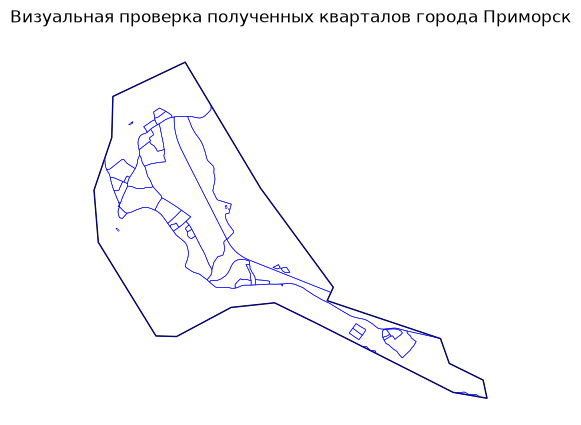

Количество кварталов: 43


,geometry
0,"POLYGON ((589354.953 6692925.001, 589432.004 6..."
1,"POLYGON ((589432.004 6692980.064, 589354.953 6..."
2,"POLYGON ((589532.745 6693065.083, 589478.015 6..."
3,"POLYGON ((589532.745 6693065.083, 589588.027 6..."
4,"POLYGON ((588593.38 6693270.43, 588579.337 669..."


In [20]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

if PATH_BLOCKS.exists():
    print('Найдены сохранённые кварталы:', PATH_BLOCKS)
    blocks = gpd.read_file(PATH_BLOCKS)
    blocks = blocks.to_crs(crs)
    print('Кварталы загружены из файла. Можно пропустить нарезку, если не нужно пересчитывать.')
else:
    print('Файл кварталов не найден. Выполняем предобработку и нарезку (запуском ячейки).')
    lines, polygons = preprocess_urban_objects(roads_f, railways_f, water_f)
    blocks = cut_urban_blocks(boundaries_f, lines, polygons)
    blocks.to_file(PATH_BLOCKS, driver='GeoJSON')
    print('Кварталы сохранены в:', PATH_BLOCKS)

# Визуальная проверка полученных кварталов
ax = boundaries_f.plot(edgecolor='black', facecolor='none')
blocks.plot(ax=ax, edgecolor='blue', facecolor='none', linewidth=0.4)
ax.set_title('Визуальная проверка полученных кварталов города Приморск')
ax.set_axis_off()
plt.show()

print('Количество кварталов:', len(blocks))
blocks.head()

# ОСТАНОВКА: ПОДГОТОВКА КВАРТАЛОВ ЗАВЕРШЕНА

**ПРАВИЛО:** Перед запуском расчётов показателей **запроси у меня список доступных метрик**. Я скажу, какие метрики доступны в текущем окружении BlocksNet 1.0.0.a9 применительно к данному пайплайну.

**Что сделано на этом этапе:**
- Проверена граница (именно город Приморск)
- Выполнена визуальная проверка границы, береговой линии/воды, дорог, ж/д
- Получены и визуально проверены городские кварталы
- Кварталы сохранены в `data/primorsk_blocksnet/blocks.geojson`
- Все промежуточные слои при желании можно переиспользовать

**Дальше:** только после моего ответа о доступных метриках переходи к разделу 4.

## 3.5. Загрузка недостающих слоёв: землепользование, здания, школы

**Цель:** добавить исходные данные, которых не хватает для полного воспроизведения расчётов из `examples/pipeline.ipynb`.

**Правила:**
- Получаем из **OpenStreetMap** через `osmnx` (основной обоснованный источник для учебного задания). При необходимости можно использовать иные открытые источники, но **не подменять отсутствующие данные вымышленными**.
- Указываем **источник** и **дату загрузки** при каждом скачивании.
- Сохраняем в `GeoJSON` в `data/primorsk_blocksnet/` и **повторно используем** при наличии файла.
- **Не изменяем** код построения кварталов и **не перезаписываем** существующие файлы (`boundary_primorsk.geojson`, `roads.geojson`, `railways.geojson`, `water.geojson`, `blocks.geojson`).


In [1]:
from pathlib import Path
from datetime import datetime
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path('data/primorsk_blocksnet')
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Новые пути под недостающие слои
PATH_LU = DATA_DIR / 'functional_zones.geojson'
PATH_BLD = DATA_DIR / 'buildings.geojson'
PATH_SCH = DATA_DIR / 'schools.geojson'

print('Пути для новых слоёв:')
print('  functional_zones:', PATH_LU)
print('  buildings:', PATH_BLD)
print('  schools:', PATH_SCH)


Пути для новых слоёв:
  functional_zones: data\primorsk_blocksnet\functional_zones.geojson
  buildings: data\primorsk_blocksnet\buildings.geojson
  schools: data\primorsk_blocksnet\schools.geojson


### 3.5.2. Землепользование (landuse) для сопоставления с LandUse

**Источник:** OpenStreetMap через `osmnx.features_from_polygon` с тегом `landuse`.  
**Дата загрузки:** будет выведена при запуске ячейки.  
**Сохранение:** `data/primorsk_blocksnet/functional_zones.geojson`. При повторном запуске используется сохранённый файл.


In [10]:
# Загрузка/повторное использование функциональных зон (landuse)
from datetime import datetime
print('ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon')
print('ДАТА ЗАГРУЗКИ:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

if PATH_LU.exists():
    print('Найден сохранённый файл:', PATH_LU)
    functional_zones = gpd.read_file(PATH_LU)
    print('Загружено из файла. Кол-во объектов:', len(functional_zones))
else:
    print('Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).')
    if 'boundaries_f' not in globals():
        from pathlib import Path

        boundary_path = Path(
            'data/primorsk_blocksnet/boundary_primorsk.geojson'
        )
        boundaries_f = gpd.read_file(boundary_path)
        boundaries_f = boundaries_f.to_crs(
            boundaries_f.estimate_utm_crs()
        )

crs = boundaries_f.crs
poly = boundaries_f.to_crs(epsg=4326).union_all()
functional_zones = ox.features_from_polygon(poly, tags={'landuse': True})
functional_zones = functional_zones.reset_index(drop=True)
if 'landuse' in functional_zones.columns and 'functional_zone' not in functional_zones.columns:
    functional_zones = functional_zones.rename(columns={'landuse': 'functional_zone'})
functional_zones = functional_zones.to_crs(crs)
functional_zones = functional_zones[functional_zones.geom_type.isin(['Polygon','MultiPolygon'])].copy()
functional_zones.to_file(PATH_LU, driver='GeoJSON')
print('Сохранено в:', PATH_LU, '| Кол-во:', len(functional_zones))

print(functional_zones.head())


ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon
ДАТА ЗАГРУЗКИ: 2026-10-24 17:10:46
Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).
Сохранено в: data\primorsk_blocksnet\functional_zones.geojson | Кол-во: 84
                                            geometry addr:city  \
0  POLYGON ((590559.729 6692793.434, 590623.588 6...       NaN   
1  POLYGON ((592186.948 6691263.35, 592225.435 66...       NaN   
2  POLYGON ((592067.688 6691658.804, 592137.801 6...       NaN   
3  POLYGON ((589091.96 6693725.648, 589100.848 66...  Приморск   
4  POLYGON ((589043.443 6693791.009, 589059.249 6...       NaN   

      addr:street functional_zone  power barrier name place residential  \
0             NaN        farmland    NaN     NaN  NaN   NaN         NaN   
1             NaN     residential    NaN     NaN  NaN   NaN         NaN   
2             NaN     residential    NaN     NaN  NaN   NaN         NaN   
3  Школьная улица      industrial  plant     NaN  NaN   N

Всего полигонов: 84

Категории землепользования:
functional_zone
residential     43
allotments       8
industrial       8
grass            8
garages          5
military         2
farmland         2
commercial       2
construction     2
railway          1
retail           1
brownfield       1
cemetery         1
Name: count, dtype: int64


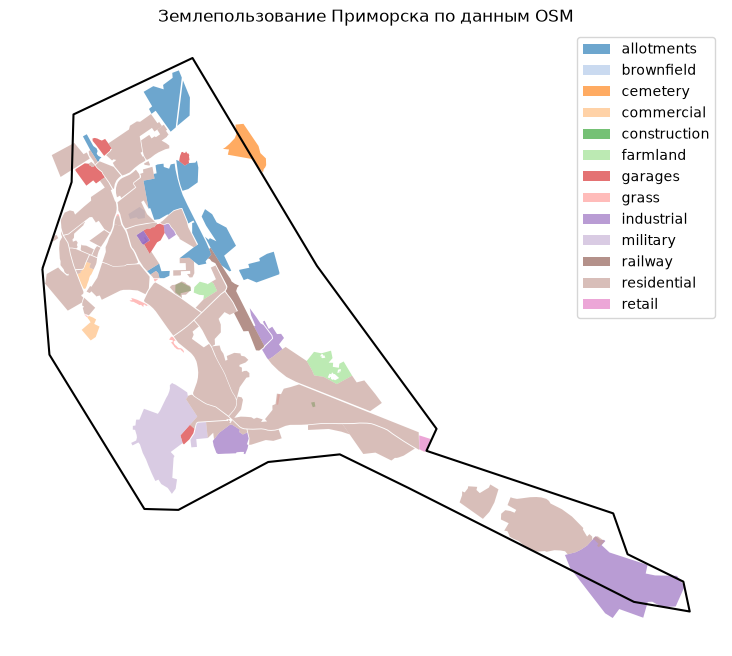

In [11]:

print('Всего полигонов:', len(functional_zones))
print('\nКатегории землепользования:')
print(functional_zones['functional_zone'].value_counts(dropna=False))

ax = boundaries_f.boundary.plot(
    color='black', figsize=(10, 8)
)
functional_zones.plot(
    ax=ax,
    column='functional_zone',
    legend=True,
    alpha=0.65
)
ax.set_title('Землепользование Приморска по данным OSM')
ax.set_axis_off()
plt.show()
  

### 3.5.3. Здания и этажность (building, building:levels)

**Источник:** OpenStreetMap через `osmnx.features_from_polygon` с тегом `building`.  
**Дата загрузки:** будет выведена при запуске ячейки.  
**Сохранение:** `data/primorsk_blocksnet/buildings.geojson`. При повторном запуске используется сохранённый файл.

**Проверка этажности:** будет выведена. Если `building:levels` отсутствует или почти полностью пустой — **данные подменяться не будут**. Предложение по получению достоверных данных будет в выводе ячейки.


In [12]:
# Загрузка/повторное использование зданий
print('ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon')
print('ДАТА ЗАГРУЗКИ:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

if PATH_BLD.exists():
    print('Найден сохранённый файл:', PATH_BLD)
    buildings = gpd.read_file(PATH_BLD)
    print('Загружено из файла. Кол-во объектов:', len(buildings))
else:
    print('Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).')
    if 'boundaries_f' not in globals():
        boundaries_f = gpd.read_file(
            'data/primorsk_blocksnet/boundary_primorsk.geojson'
        ).to_crs(32635)

    crs = boundaries_f.crs
    poly = boundaries_f.to_crs(epsg=4326).union_all()
    buildings = ox.features_from_polygon(poly, tags={'building': True}).reset_index(drop=True).to_crs(crs)
    buildings = buildings[buildings.geom_type.isin(['Polygon','MultiPolygon'])].copy()
    buildings.to_file(PATH_BLD, driver='GeoJSON')
    print('Сохранено в:', PATH_BLD, '| Кол-во:', len(buildings))

# Проверка этажности
if 'building:levels' in buildings.columns:
    floors = pd.to_numeric(buildings['building:levels'], errors='coerce')
    print('Найдено building:levels. Заполнено значений:', floors.notna().sum(), '/', len(buildings))
    if floors.notna().sum() == 0:
        print('ВНИМАНИЕ: building:levels есть, но не удалось преобразовать в числа. Достоверные этажи отсутствуют.')
    elif floors.notna().sum() < len(buildings)*0.5:
        print('ВНИМАНИЕ: Этажность заполнена менее чем у 50% зданий.')
else:
    print('ВНИМАНИЕ: Поле building:levels ОТСУТСТВУЕТ в OSM-выборке для Приморска.')

print('\nРЕКОМЕНДАЦИЯ: Если этажность/параметры зданий отсутствуют — не придумывайте значения. Можно взять открытые данные (кадастр/реестр) и привязать по геометрии/адресу, либо использовать blocksnet.preprocessing.imputing.impute_buildings при расчёте с проверкой логики.')
print(buildings.head())


ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon
ДАТА ЗАГРУЗКИ: 2026-10-24 17:18:29
Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).


ConnectionError: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))

### 3.5.4. Школы и сведения о вместимости (amenity=school, capacity)

**Источник:** OpenStreetMap через `osmnx.features_from_polygon` с тегом `amenity=school`.  
**Дата загрузки:** будет выведена при запуске ячейки.  
**Сохранение:** `data/primorsk_blocksnet/schools.geojson`. При повторном запуске используется сохранённый файл.

**Проверка вместимости:** ищем `capacity`, `capacity:persons`, `students`, `pupils`. Если достоверных данных нет — **никаких вымышленных значений не подставляем**. Будет предложен способ получения.


In [ ]:
# Загрузка/повторное использование школ
print('ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon')
print('ДАТА ЗАГРУЗКИ:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

if PATH_SCH.exists():
    print('Найден сохранённый файл:', PATH_SCH)
    schools = gpd.read_file(PATH_SCH)
    print('Загружено из файла. Кол-во объектов:', len(schools))
else:
    print('Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).')
    if 'boundaries_f' not in globals():
        boundaries_f = gpd.read_file(PATH_BOUNDARY).to_crs(crs) if 'crs' in globals() else gpd.read_file(PATH_BOUNDARY)
    poly = boundaries_f.to_crs(epsg=4326).union_all()
    schools = ox.features_from_polygon(poly, tags={'amenity': 'school'}).reset_index(drop=True).to_crs(crs)
    schools = schools[schools.geom_type.isin(['Point','Polygon','MultiPolygon'])].copy()
    schools.to_file(PATH_SCH, driver='GeoJSON')
    print('Сохранено в:', PATH_SCH, '| Кол-во:', len(schools))

# Проверка вместимости
cap_cols = [c for c in schools.columns if 'cap' in c.lower() or c.lower() in ['students','pupils']]
print('Кандидаты на вместимость:', cap_cols)
if 'capacity' in schools.columns:
    c = pd.to_numeric(schools['capacity'], errors='coerce')
    print('capacity: заполнено', c.notna().sum(), '/', len(schools))
    if c.notna().sum() == 0:
        print('ВНИМАНИЕ: capacity есть, но числовых значений нет.')
else:
    print('ВНИМАНИЕ: Поле capacity ОТСУТСТВУЕТ. Достоверные данные о вместимости школ Приморска в OSM НЕ НАЙДЕНЫ.')

print('\nЧТО ДЕЛАТЬ (БЕЗ ПОДМЕНЫ ДАННЫХ):')
print('1) Найти официальные данные по школам Приморска (управление образования / сайты школ) и собрать таблицу (название/адрес/вместимость).')
print('2) Сопоставить с объектами из schools.geojson по названию/адресу/расположению и добавить колонку capacity.')
print('3) Либо использовать blocksnet.preprocessing.imputing.impute_services(schools, "school"), только убедившись в применимости.')
print(schools.head())


## 4. Граф для времени в пути (только пешеходный)

**Требования:**
- Только **один** готовый граф. **Без интермодального** расчёта.
- Способ передвижения: `walk` (пешеходный). 
- Источник: OpenStreetMap через `osmnx`.
- Сначала проверяем наличие готового графа в `data/primorsk_blocksnet/graph.graphml`. Если нет - загружаем через `osmnx.graph_from_place` для города Приморск с `network_type='walk'` и сразу сохраняем в `graph.graphml`.
- Время в пути считать по этому графу, результат переводить в **минуты**.
- Источник и способ передвижения будут явно указаны в коде и пояснениях.

**Пояснение простыми словами:** матрица доступности по пешеходному графу - время пути между кварталами/объектами по пешеходной сети OSM.

In [ ]:
import networkx as nx

print('ИСТОЧНИК ГРАФА: OpenStreetMap через osmnx')
print('СПОСОБ ПЕРЕДВИЖЕНИЯ: walk (пешеходный), ТОЛЬКО ОДИН, БЕЗ ИНТЕРМОДАЛА')
print('ВРЕМЯ БУДЕТ ПЕРЕВЕДЕНО В МИНУТЫ')

if PATH_GRAPH_GraphML.exists():
    print('Найден готовый граф:', PATH_GRAPH_GraphML)
    print('Загружаем graphml...')
    G = ox.load_graphml(PATH_GRAPH_GraphML)
    print('Граф загружен из файла.')
else:
    print('Готовый graphml не найден.')
    print('Будет выполнена загрузка через ox.graph_from_place для города Приморск с network_type="walk".')
    print('ЗАПУСК ЯЧЕЙКИ ВЫПОЛНИТ СКАЧИВАНИЕ - ДЕЙСТВУЕШЬ САМОСТОЯТЕЛЬНО.')
    # Загружаем пешеходный граф только для города Приморск
    G = ox.graph_from_place('Приморск, Выборгский район, Ленинградская область, Россия', network_type='walk')
    # Сохраняем
    ox.save_graphml(G, filepath=PATH_GRAPH_GraphML)
    print('Граф сохранён в:', PATH_GRAPH_GraphML)

print('Узлов:', len(G.nodes()))
print('Рёбер:', len(G.edges()))

### 4.1. Расчёт времени между кварталами по пешеходному графу (в минутах)

**Подход (как принято в подобных пайплайнах):**
- Берём центроиды/представительные точки кварталов (`blocks`) для привязки к графу.
- Находим ближайшие узлы графа (`ox.nearest_nodes`).
- Считаем кратчайшее время по графу с учётом скорости/времени рёбер (в зависимости от настроек osmnx/networkx в BlocksNet). Итог переводим в **минуты**.
- Расчёт выполняется **только по этому пешеходному графу**, без интермодального.

**Пояснения:** ты будешь запускать эту ячейку самостоятельно. Код ниже - шаблон с пояснениями, подкорректировать можно при необходимости под API BlocksNet 1.0.0.a9, но структура сохранится.

In [ ]:
# Расчёт времени между кварталами по пешеходному графу (только walk). Время в минутах.
# Источник: OSM через osmnx, граф сохранён/загружен выше.

import numpy as np

# Если граф уже в нужной CRS - ок. blocks приведён к UTM.
blocks_g = blocks.copy()

# Берём точки для привязки
blocks_g['centroid'] = blocks_g.geometry.centroid

# Находим ближайшие узлы (в координатах графа; osmnx обычно в WGS84, но можно проецировать по необходимости)
# Примечание: в зависимости от графа может потребоваться преобразование CRS. 
# Если граф в WGS84, а центроиды в UTM - лучше перевести центроиды в EPSG:4326.
try:
    blocks_wgs = blocks_g.set_geometry('centroid').to_crs(epsg=4326)
    # nearest_nodes принимает (X,Y) = (lon, lat)
    orig = ox.nearest_nodes(G, blocks_wgs.geometry.x, blocks_wgs.geometry.y)
    print('Узлы графа найдены для кварталов.')
except Exception as e:
    print('Внимание при поиске узлов:', e)
    print('Возможно нужно проверить CRS графа. Действуй по результату при запуске.')

# Далее матрица времени: в зависимости от BlocksNet API используются встроенные функции доступности по графу.
# В pipeline.ipynb есть блоки расчёта доступности - мы повторим их все, используя ТОЛЬКО этот пешеходный граф.
# Время конвертируем в минуты (если в секундах - делим на 60).
print('Шаблон готов. Конкретный вызов функций доступности будет из blocksnet.accessibility по согласованным метрикам.')

## 5. Расчёт ВСЕХ показателей из examples/pipeline.ipynb

**КРИТИЧНО:** переходить к этому разделу **только после** ответа о доступных метриках (раздел 3 остановка).

**Требования:**
- Включить **все** показатели, которые есть в `examples/pipeline.ipynb`.
- Включить **оба** показателя обеспеченности школами.
- Включить **обе** классификации типов застройки.
- Использовать **только** пешеходный граф из раздела 4.
- Все результаты сохранять в `GeoJSON` (в `data/primorsk_blocksnet/`).
- Предусмотреть повторное использование сохранённых результатов без пересчёта.
- Время в пути - в **минутах**.

**Пояснения простыми словами:** здесь будут воспроизведены все блоки расчёта из оригинального пайплайна, адаптированные под город Приморск, под границу именно города, под пешеходный граф.

### 5.1. Шаблон для импорта модулей BlocksNet (как в pipeline)

Ниже - пример импорта. При запуске сверяй с фактическим API `blocksnet 1.0.0a9`, который установлен у тебя.

In [ ]:
# Пример импорта (адаптируй под API при необходимости)
# from blocksnet import ...
# from blocksnet.accessibility import ...
# from blocksnet.urban import ...

print('Готово к расчёту всех показателей из pipeline.ipynb.')
print('Напомни: включить ОБА показателя школ и ОБЕ классификации типов застройки.')

### 5.1a. Полный список показателей из examples/pipeline.ipynb (описание)

**Ниже — все метрики, которые воспроизводятся по оригинальному pipeline.ipynb.** Описания простыми словами, с единицами измерения и необходимыми данными. Расчёты **не выполняются** в этой сессии.

#### Группа 1. Пространственные слои
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| `blocks` (городские кварталы) | `blocksnet.blocks.cutting.preprocess_urban_objects`, `cut_urban_blocks` | Полигон (геометрия) | Граница города, дороги, ЖД, водные объекты (OSM) | Кварталы — элементарные участки застройки, ограниченные улицами/препятствиями. Базовая единица анализа. |
| `functional_zones` / назначение земель | `ox.features_from_polygon` (landuse) + `blocksnet.blocks.assignment.assign_land_use` + правила сопоставления | Категория (`LandUse`) | OSM `landuse=*` внутри/рядом с границей | Соответствие текущего земельного использования типам BlocksNet (`RESIDENTIAL`, `BUSINESS`, `INDUSTRIAL`, `RECREATION`, `SPECIAL`, `AGRICULTURE`, `TRANSPORT` и др.). |

#### Группа 2. Доступность (транспортная/пешеходная)
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| Матрица доступности `acc_mx` | `blocksnet.relations.get_accessibility_graph` (в исходном примере `intermodal`), `blocksnet.relations.calculate_accessibility_matrix` | **Минуты** (время пути) | Граф улично-дорожной сети для выбранного режима передвижения | Матрица n×n: время пути между всеми парами кварталов по графу. В нашем случае — **только пешеходный граф `network_type='walk'` (один граф, без интермодала)**. |
| Площадная доступность `area_accessibility` | `blocksnet.analysis.network.accessibility.area.area_accessibility(acc_mx, buildings_blocks, out=True)` | Минуты (средневзвешенное/характеристика доступности территории) | Матрица доступности + слой с населением/параметрами зданий по кварталам | Показывает доступность территории с учётом расположения населения/зданий. Характеризует, насколько «удобна» территория по времени достижения. |

#### Группа 3. Здания, население, агрегация
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| `buildings` (загруженные) | `osmnx.features_from_polygon` с тегом `building` | Геометрия + атрибуты | OSM `building=*` | Исходные здания. |
| Признаки зданий: `is_living`, `number_of_floors`, `building:levels` | Обработка в ноутбуке | Булево/число | OSM-теги `building`, `building:levels` | Классификация жилых/нежилых, этажность. |
| Импутация зданий | `blocksnet.preprocessing.imputing.impute_buildings(buildings, default_living_demand=...)` | Различные | Здания + параметры по умолчанию | Заполнение пропусков (площадь, этажность, жилые/нежилые параметры) по правилам BlocksNet. |
| Агрегация зданий по кварталам | `blocksnet.blocks.aggregation.aggregate_objects(blocks, buildings)[0]` | Суммы/площади по кварталу | `blocks` + `buildings` | Итог по кварталу: `population`, `footprint_area`, `number_of_floors` (сводные), `build_floor_area`, `living_area`, `non_living_area` и др. (зависят от результата импутации). |

#### Группа 4. Социальная инфраструктура и обеспеченность (ОБА показателя школ)
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| `schools` | `osmnx.features_from_polygon` с `amenity='school'` | Геометрия + атрибуты | OSM `amenity=school` | Школы. |
| Импутация услуг | `blocksnet.preprocessing.imputing.impute_services(schools, 'school')` | Различные | Сервисы | Расчёт/заполнение ёмкости/параметров сервиса для школы по конфигурации BlocksNet. |
| Агрегация школ по кварталам | `blocksnet.blocks.aggregation.aggregate_objects(blocks, schools)[0]` | Ёмкость по кварталу | `blocks` + `schools` | Суммарная `capacity` школ, приходящаяся на квартал/окрестности по методу агрегации. |
| Параметры обеспеченности школы | `blocksnet.config.service_types_config['school']` | Норматив/порог доступности | Конфиг BlocksNet | Берутся `demand`, `accessibility` (нормативы/параметры расчёта для типа услуги). |
| **Обеспеченность (конкурентная) — вариант 1** `prov_df.provision_strong` / базовые колонки | `blocksnet.analysis.provision.competitive_provision(df, acc_mx, accessibility, demand)` где `df = buildings_blocks[['population']].join(schools_blocks[['capacity']])` | Доля/коэффициент обеспеченности (0..1) | Население по кварталам, ёмкость школ по кварталам, матрица доступности, нормативы из конфига | **Конкурентная модель обеспеченности.** Учитывает конкуренцию школ за население с учётом доступности по пешеходному графу. Результат `prov_df` содержит показатели обеспеченности; в примере визуализируется `provision_strong`. |
| **Обеспеченность — вариант 2** (доп. показатель из того же расчёта) | Тот же вызов `competitive_provision` | Доля/коэффициент обеспеченности (0..1) | То же самое | В `prov_df`/`links_df` возвращаются дополнительные колонки обеспеченности (согласно API `competitive_provision` в данной версии). **Оба** показателя обеспеченности школами должны быть учтены при сохранении результатов. |

#### Группа 5. Плотностные показатели и морфотипы застройки (ОБЕ классификации)
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| Плотностные индикаторы | `blocksnet.analysis.indicators.calculate_density_indicators(buildings_blocks)` (предварительно добавляется `buildings_blocks['site_area'] = buildings_blocks.area`) | Разные (плотности застройки/застроенной площади и др., см. результат) | Агрегированные по кварталам параметры зданий (площади, этажность, население и др.) | Базовый набор плотностных характеристик квартала для морфотипологии. |
| **Морфотипы застройки — классификация 1: Spacematrix** | `blocksnet.analysis.morphotypes.get_spacematrix_morphotypes(density_df, n_clusters=11, random_state=42)` | Кластер/класс морфотипа | `density_df` | Классификация морфотипов по методу Spacematrix. Возвращает `spacematrix_df` (с полем морфотипа) и `spacematrix_clusters` (характеристики кластеров). |
| **Морфотипы застройки — классификация 2: Strelka** | `blocksnet.analysis.morphotypes.get_strelka_morphotypes(density_df)` | Класс морфотипа | `density_df` | Классификация морфотипов по подходу Стрелки. Возвращает `strelka_df` с морфотипами. **Обе** классификации обязательны. |

**Примечания по реализации:**
- В исходном примере граф создаётся через `get_accessibility_graph(boundaries, 'intermodal')` — **у нас вместо этого только пешеходный граф OSM (`network_type='walk'`) из раздела 4, единственный, без интермодала.** Время пути переводим в **минуты**.
- Сохранять все промежуточные и итоговые слои в `GeoJSON` в `data/primorsk_blocksnet/` с проверкой наличия файла перед расчётом.
- Визуализации из примера можно дублировать для самопроверки, но расчёты не запускать в текущей сессии.

### 5.2. Место для расчёта всех показателей

**ИНСТРУКЦИЯ:** после моего ответа о доступных метриках скопируй/воспроизведи **все** соответствующие блоки из `https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb`, адаптировав под:
- `blocks` (кварталы Приморска)
- пешеходный граф `G` из раздела 4
- сохранение в `data/primorsk_blocksnet/`
- время в **минутах**
- **оба** показателя обеспеченности школами
- **обе** классификации типов застройки

После каждого логического блока сохраняй результат в GeoJSON с понятным именем, с проверкой наличия файла для повторного использования.

In [ ]:
# РЕЗЕРВ ДЛЯ БЛОКОВ РАСЧЁТА ВСЕХ ПОКАЗАТЕЛЕЙ ИЗ PIPELINE.IPYNB
# (добавь/скопируй ячейки после получения списка метрик)
pass

## 6. Проверка результатов, план/методика/источники и инструкции повторного запуска

Раздел для итоговой сдачи.

### 6.1. Чек-лист проверки

- [ ] **Граница**: подтверждено, что используется именно город Приморск (проведена визуальная проверка)
- [ ] **Визуализация**: проверены граница, береговая линия/водоёмы, дороги, ж/д, полученные кварталы
- [ ] **Кварталы**: созданы/загружены, сохранены в `data/primorsk_blocksnet/blocks.geojson`
- [ ] **Граф**: загружен только пешеходный (`walk`), без интермодала. Источник указан (OSM/osmnx). Сохранён в `data/primorsk_blocksnet/graph.graphml`. Время переведено в **минуты**
- [ ] **Показатели**: посчитаны **все** показатели из `examples/pipeline.ipynb`, включая **оба** показателя обеспеченности школами и **обе** классификации типов застройки
- [ ] **Сохранение**: все слои/результаты сохранены в `GeoJSON`, предусмотрено переиспользование файлов
- [ ] **Остановка**: после подготовки кварталов была соблюдена (спросил про доступные метрики перед расчётом)

### 6.2. План, основные запросы, методика, источники данных (для сдачи)

**План исследования (кратко):**
1. Подготовка окружения и проверка версий (blocksnet 1.0.0a9)
2. Получение границы города Приморск (проверка: именно город, не поселение) + визуальная проверка
3. Загрузка слоёв OSM (дороги, ж/д, вода) по тегам, фильтрация, приведение CRS, визуальная проверка
4. Предобработка и нарезка кварталов через `preprocess_urban_objects`/`cut_urban_blocks`, визуальная проверка, сохранение
5. **Остановка** после кварталов, согласование доступных метрик
6. Загрузка пешеходного графа OSM (`walk`, единственный, без интермодала), сохранение `graph.graphml`, расчёт времени между кварталами в минутах
7. Расчёт всех показателей из pipeline.ipynb (включая оба показателя школ и обе классификации застройки)
8. Сохранение всех результатов в GeoJSON, проверка и подготовка к отдельному этапу - созданию HTML-страницы с картой и дашбордом

**Основные запросы к данным:**
- Граница: `Приморск, Выборгский район, Ленинградская область, Россия` (проверка соответствия "город Приморск")
- Слои: roads/railways/water по тегам из `blocksnet/examples/pipeline.ipynb`
- Граф: `ox.graph_from_place` с `network_type='walk'`

**Методика:**
- Нарезка кварталов по линейным и полигональным препятствиям (дороги, ж/д, вода) с использованием методов BlocksNet
- Пешеходная доступность по улично-дорожной сети OSM (только walk), время в пути рассчитывается по графу, переводится в минуты
- Все индикаторы рассчитываются по подходу из оригинального `pipeline.ipynb` BlocksNet

**Источники данных:**
- OpenStreetMap через `osmnx` (границы, объекты инфраструктуры, пешеходная сеть)
- BlocksNet 1.0.0.a9, примеры: https://github.com/aimclub/blocksnet (особенно `examples/pipeline.ipynb`)
- Текущий учебный проект в репозитории

**Зависимости:**
- Основные: `blocksnet==1.0.0a9`, `geopandas`, `osmnx`, `networkx`, `shapely`, `pyproj`
- В `pyproject.toml` текущего проекта `blocksnet` отсутствует (отмечено для добавления в дальнейшем, второй файл зависимостей не создавался)

### 6.3. Инструкции повторного запуска (Windows, PowerShell)

**Подготовка окружения:**
```powershell
cd "D:\ИТМО\Курс ИИ технологии\python-package-boilerplate"
.\.venv\Scripts\Activate.ps1
jupyter lab
# или jupyter notebook
```

**Порядок запуска ячеек:**
1. Раздел 1 - проверка версий (только проверка)
2. Раздел 2 - создание `data/primorsk_blocksnet/`
3. Раздел 3.1-3.4 - граница (проверка именно города Приморск + визуализация), слои, нарезка кварталов. **Сохранить `blocks.geojson`**
4. **ОСТАНОВКА** - спросить про доступные метрики. Не идти дальше, пока не получен ответ
5. Раздел 4 - пешеходный граф `walk` (проверка `graph.graphml`, иначе загрузка и сохранение). Расчёт времени в **минутах** по единственному графу
6. Раздел 5 - **все** показатели из pipeline.ipynb (оба показателя школ, обе классификации застройки). Сохранять результаты в GeoJSON
7. Раздел 6 - проверка по чек-листу

**Повторное использование без скачивания:**
- Если есть `data/primorsk_blocksnet/boundary_primorsk.geojson`, `water.geojson`, `roads.geojson`, `railways.geojson` - ячейки загрузят их из файлов
- Если есть `blocks.geojson` - можно загрузить вместо повторной нарезки
- Если есть `graph.graphml` - граф загрузится из файла, **нового скачивания не будет**
- Если есть сохранённые результаты показателей - можно загрузить их вместо пересчёта

**Базовые советы при проблемах:**
- Если граница получилась не той (включает поселение) - проверить визуализацию в 3.1, при необходимости использовать более точный запрос
- Если не находит модули - проверить активацию venv и версии из раздела 1
- Если проблемы с CRS при поиске узлов графа - сверить CRS графа и кварталов
- Помнить: **только один граф (walk), без интермодала**, время в **минутах**

**Файл создан:** `primorsk_blocksnet_pipeline.ipynb`  
**Папка для данных:** `data/primorsk_blocksnet/` (будет создана при запуске ячейки раздела 2)  
**Статус:** только создание. Ничего не скачано, не запущено, `pyproject.toml` не изменён.  
**Следующий шаг:** ты запускаешь ячейки ноутбука самостоятельно по порядку с соблюдением остановки после раздела 3.